
# 🎬 Netflix Movies and TV Shows – Exploratory Data Analysis (EDA)

## 1. Introduction

Netflix is one of the world's leading streaming platforms, offering a wide variety of movies and TV shows across different countries, genres and languages. With its growing content library, understanding the distribution and characteristics of its catalogue is important for identifying content trends and patterns.

This project focuses on performing **Exploratory Data Analysis (EDA)** on the Netflix Movies and TV Shows dataset to uncover meaningful insights about its content library.

## 2. Objectives

The main objectives of this analysis are:

- Analyze the distribution of Movies and TV Shows available on Netflix.
- Identify content addition and release trends over the years.
- Explore country-wise content distribution.
- Identify the most common genres and content categories.
- Analyze content maturity ratings.
- Understand the distribution of TV Shows based on the number of seasons.
- Examine the time gap between a title's release and its addition to Netflix.
- Identify patterns that can support content planning and catalogue diversification.

## 3. Dataset Overview

The dataset contains information about Netflix Movies and TV Shows, including:

- **show_id:** Unique identifier for each title.
- **type:** Indicates whether the title is a Movie or TV Show.
- **title:** Name of the movie or TV show.
- **director:** Director of the title.
- **cast:** Actors and actresses featured in the title.
- **country:** Country where the title was produced.
- **date_added:** Date the title was added to Netflix.
- **release_year:** Original release year.
- **rating:** Content maturity rating.
- **duration:** Movie runtime or number of TV Show seasons.
- **listed_in:** Genres or categories associated with the title.
- **description:** Short description of the title.

## 4. Tools and Technologies

- **Python:** Data analysis and manipulation.
- **Pandas:** Data cleaning and data manipulation.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical data visualization.
- **Jupyter Notebook:** Development and presentation of the analysis.

## 5. Problem Statement

The objective is to analyze Netflix's content catalogue and identify meaningful patterns related to content types, release trends, genres, countries and maturity ratings. The findings will help understand the composition of the catalogue and provide data-driven recommendations for content planning and diversification.

## 6. Expected Outcome

The analysis aims to transform raw Netflix catalogue data into meaningful insights through data cleaning, statistical exploration and visualizations. These insights will help identify content trends, understand catalogue diversity and highlight potential opportunities for future content strategies.


### Import necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Visualization theme

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

NETFLIX_RED = "#E50914"
DARK_RED = "#B20710"
BLACK = "#141414"
DARK_GREY = "#454545"
GREY = "#A3A3A3"
LIGHT_GREY = "#E5E5E5"
BACKGROUND = "#FFFFFF"

sns.set_theme(style="white", context="notebook")

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": True,
    "axes.edgecolor": LIGHT_GREY,
    "axes.titleweight": "bold",
    "axes.titlesize": 17,
    "axes.labelsize": 11,
    "font.family": "DejaVu Sans",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "grid.color": LIGHT_GREY,
    "grid.alpha": 0.6,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

### Data Loading

In [3]:
df=pd.read_csv("netflix_data.csv")
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


### Understand the Data

In [4]:
df.shape

(8807, 12)

In [5]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [7]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [8]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [9]:
df.isnull().sum()/len(df)*100

show_id          0.000000
type             0.000000
title            0.000000
director        29.908028
cast             9.367549
country          9.435676
date_added       0.113546
release_year     0.000000
rating           0.045418
duration         0.034064
listed_in        0.000000
description      0.000000
dtype: float64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

In [12]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


show_id:
['s1' 's2' 's3' ... 's8805' 's8806' 's8807']

type:
['Movie' 'TV Show']

title:
['Dick Johnson Is Dead' 'Blood & Water' 'Ganglands' ... 'Zombieland'
 'Zoom' 'Zubaan']

director:
['Kirsten Johnson' nan 'Julien Leclercq' ... 'Majid Al Ansari'
 'Peter Hewitt' 'Mozez Singh']

cast:
[nan
 'Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng'
 'Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera'
 ...
 'Jesse Eisenberg, Woody Harrelson, Emma Stone, Abigail Breslin, Amber Heard, Bill Murray, Derek Graf'
 'Tim Allen, Courteney Cox, Chevy Chase, Kate Mara, Ryan Newman, Michael Cassidy, Spencer Breslin, Rip Torn, Kevin Zegers'
 'Vicky Kaushal, 

### Data Preprocessing

In [13]:
df_raw = df.copy()

##### Converting date_added to datetime format for analysis

In [14]:
df["date_added"] = pd.to_datetime(
    df["date_added"].astype("string").str.strip(),
    errors="coerce")

##### Handling missing values

In [15]:
df['director'] = df['director'].fillna('Uncredited Director')
df['cast']     = df['cast'].fillna('Uncredited Cast')
df['country']  = df['country'].fillna('Unknown Country')
df['rating']   = df['rating'].fillna('Not Rated')

In [16]:
df = df.dropna(subset=['date_added'])
df = df.dropna(subset=['duration'])

In [17]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

##### Extract year and month from date_added

In [18]:
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["month_name_added"] = df["date_added"].dt.month_name()

In [19]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,month_name_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Uncredited Cast,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,September
1,s2,TV Show,Blood & Water,Uncredited Director,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,September
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown Country,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,September
3,s4,TV Show,Jailbirds New Orleans,Uncredited Director,Uncredited Cast,Unknown Country,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9,September
4,s5,TV Show,Kota Factory,Uncredited Director,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9,September
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",2019,11,November
8803,s8804,TV Show,Zombie Dumb,Uncredited Director,Uncredited Cast,Unknown Country,2019-07-01,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...",2019,7,July
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019,11,November
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020,1,January


### Analysis 1: What type of content dominates Netflix?

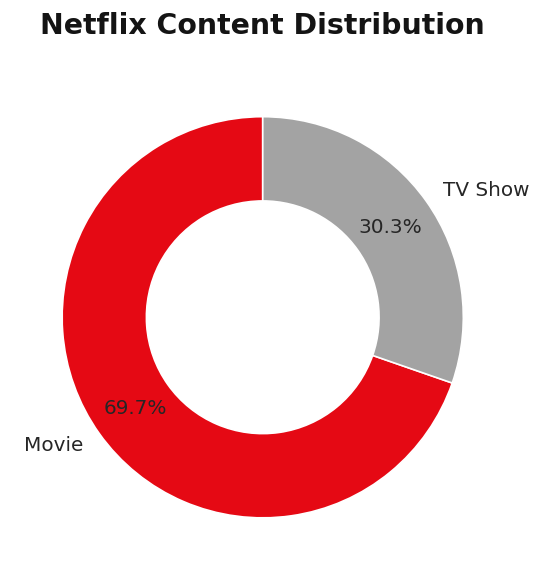

In [68]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(9, 5))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%",
    colors=[NETFLIX_RED, GREY],
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    pctdistance=0.78,
    textprops={"fontsize": 12}
)

plt.title("Netflix Content Distribution", pad=20)
plt.tight_layout()
plt.show()

`Insight:` 
- Movies account for approximately 69.6% of the catalogue, while TV Shows contribute around 30.4%.
- Netflix's catalogue has a significantly stronger representation of movies.
- The smaller TV-show share suggests an opportunity to investigate whether expanding series content could create a more balanced catalogue.

`Business recommendation:` Netflix could evaluate opportunities to expand original series and multi-season content while maintaining its strong movie library.

### Analysis 2: How has the composition of Netflix content changed across release years

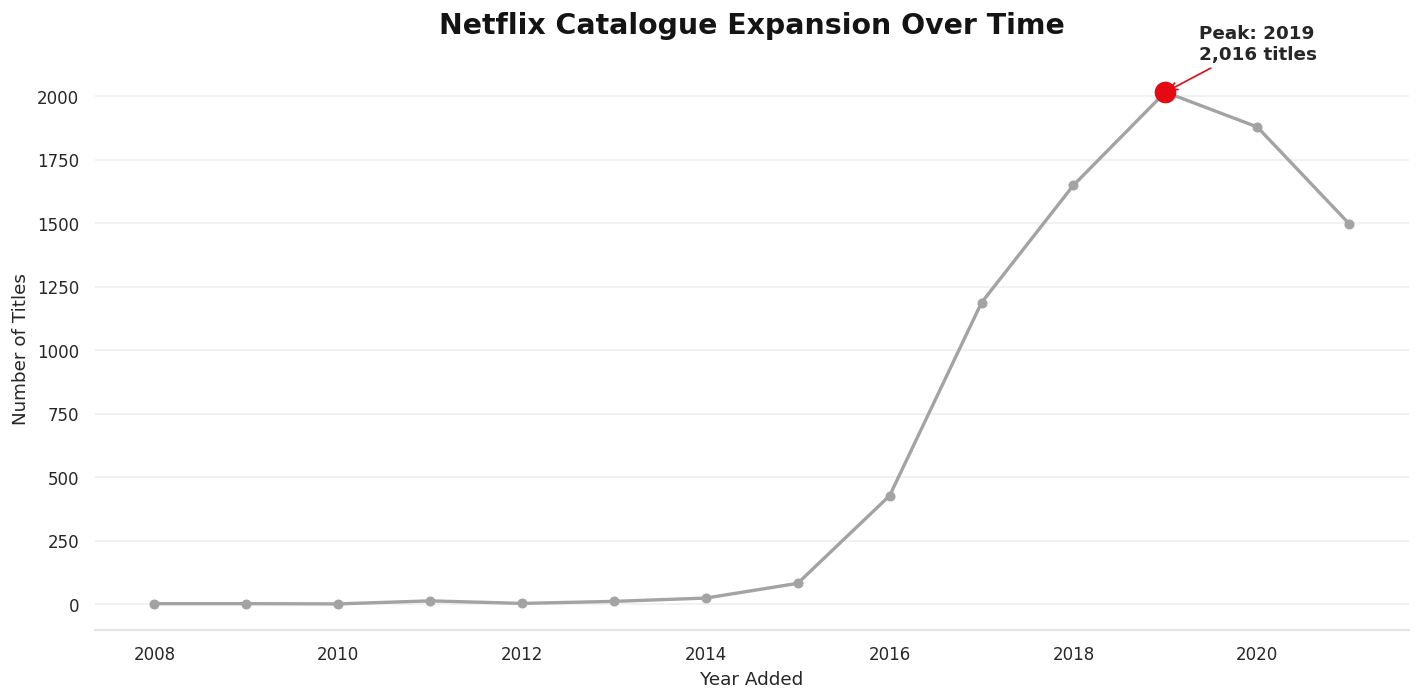

In [71]:
yearly_additions = df.groupby("year_added").size()

peak_year = yearly_additions.idxmax()
peak_value = yearly_additions.max()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    yearly_additions.index,
    yearly_additions.values,
    color=GREY,
    linewidth=2,
    marker="o",
    markersize=5
)

ax.plot(
    peak_year,
    peak_value,
    marker="o",
    color=NETFLIX_RED,
    markersize=12
)

ax.annotate(
    f"Peak: {peak_year}\n{peak_value:,} titles",
    xy=(peak_year, peak_value),
    xytext=(20, 20),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    arrowprops={"arrowstyle": "->", "color": NETFLIX_RED}
)

ax.set_title(
    "Netflix Catalogue Expansion Over Time",
    loc="center", pad=20
)

ax.set_xlabel("Year Added")
ax.set_ylabel("Number of Titles")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

`Insight:`
- The yearly additions chart identifies periods when Netflix expanded its catalogue most aggressively.
- A rise in additions indicates increased catalogue expansion during that period.
- A decline in additions may indicate a change in acquisition activity, although it does not establish the reason.

`Business recommendation:` Monitor content additions over time and evaluate whether catalogue expansion is aligned with content strategy and audience demand.

### Analysis 3: Which months have the highest number of Netflix additions?

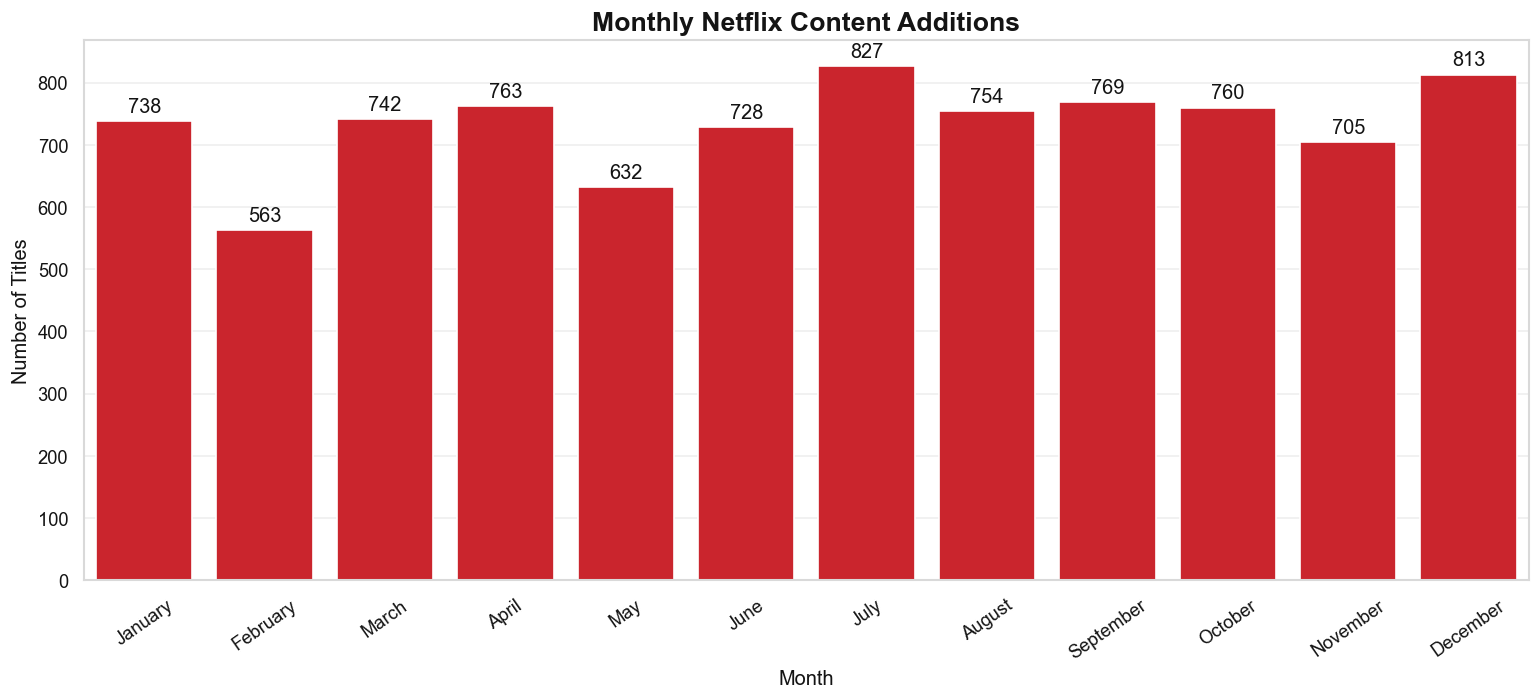

In [32]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_additions = df["month_name_added"].value_counts().reindex(
    month_order, fill_value=0
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    x=monthly_additions.index,
    y=monthly_additions.values,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Monthly Netflix Content Additions")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

`Insight:`
- The monthly trend reveals whether catalogue additions are concentrated in particular months.
- Months with higher additions represent periods of greater catalogue expansion.
- These patterns can help identify potential scheduling opportunities.

`Business recommendation:` Use historical addition patterns as one input when planning content release calendars, while considering actual audience engagement data.

### Analysis 4: Did Netflix add more movies or TV shows in different years?

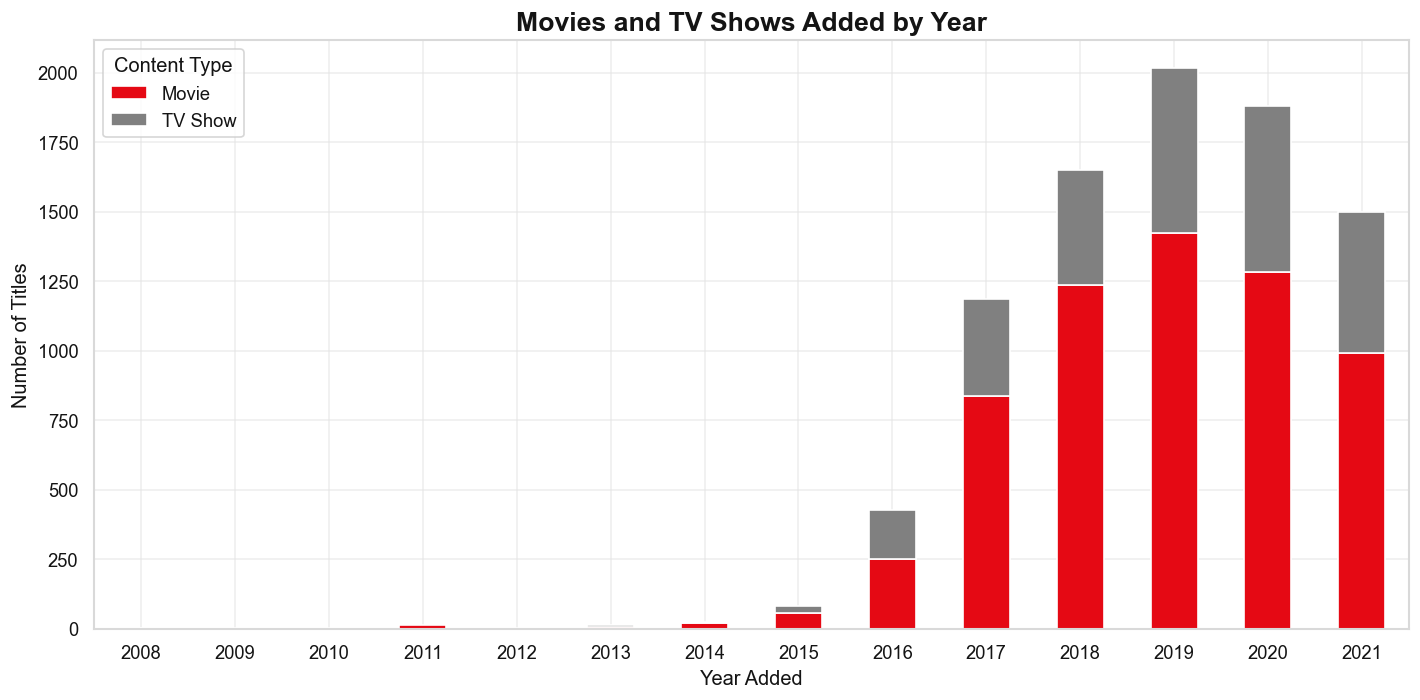

In [33]:
year_type_added = df.groupby(
    ["year_added", "type"]
).size().unstack(fill_value=0)

year_type_added.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=[NETFLIX_RED, GREY]
)

plt.title("Movies and TV Shows Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

`Insight:`
- Comparing yearly additions reveals whether Netflix relies more heavily on movies or TV Shows when expanding its catalogue.
- If movies consistently dominate additions, the content acquisition strategy may be more movie-oriented.
- Changes in the TV-show contribution can reveal shifts in the composition of the catalogue.

`Business recommendation:` Evaluate the balance between movie and TV-show acquisitions to ensure the catalogue serves different viewing preferences.

### Analysis 5: Which countries contribute the most titles to Netflix's catalogue?

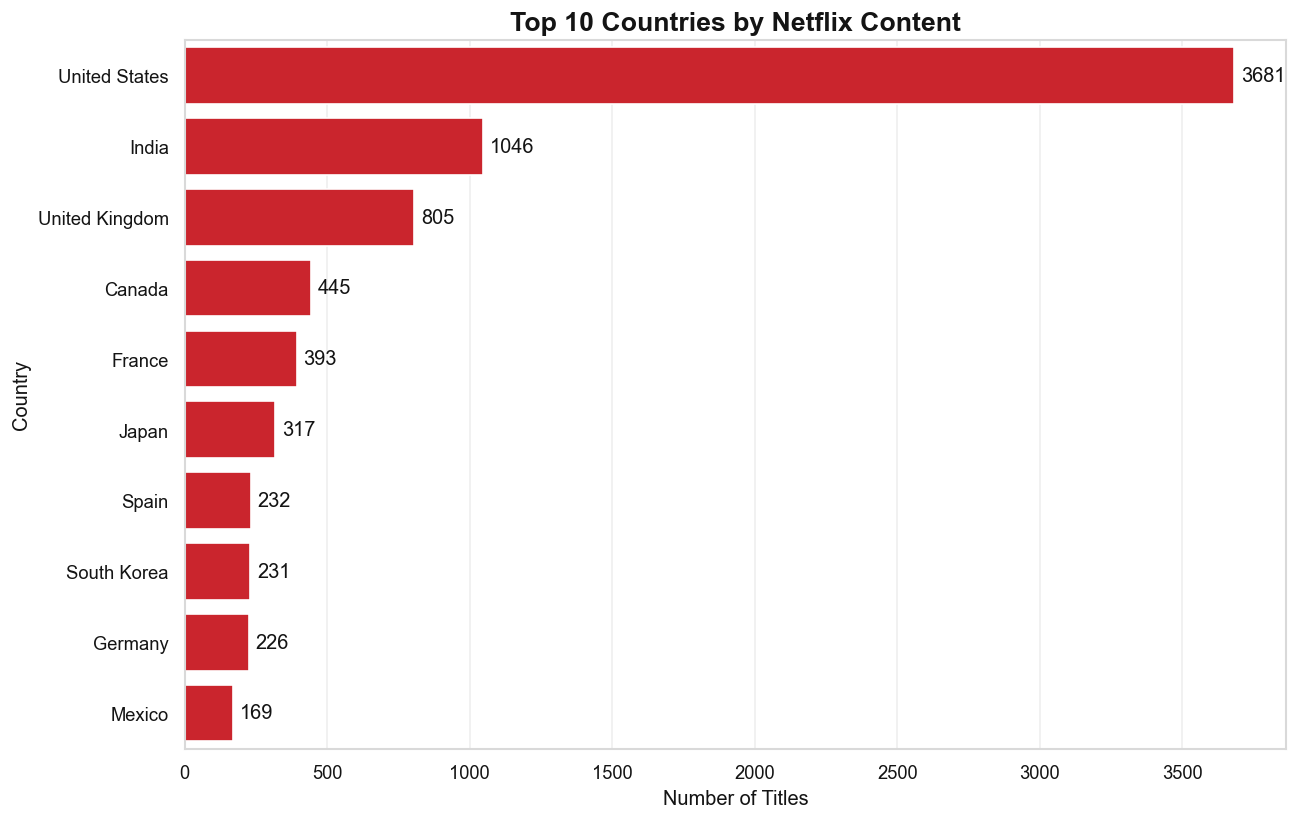

In [36]:
country_data = df[["show_id", "country"]].copy()

country_data["country"] = country_data["country"].str.split(",")

country_data = country_data.explode("country")

country_data["country"] = country_data["country"].str.strip()

country_counts = (
    country_data[country_data["country"] != "Unknown Country"]
    ["country"].value_counts().head(10)
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=4)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

`Insight:`
- The United States is the largest contributor to Netflix's catalogue in this dataset.
- Other countries, including India and the United Kingdom, also contribute to its international content library.
- The distribution highlights the importance of content from multiple production markets.

`Business recommendation:` Continue exploring regional content opportunities, especially in markets where local storytelling can strengthen catalogue diversity.

### Analysis 6: Which countries contribute more movies and which contribute more TV shows?

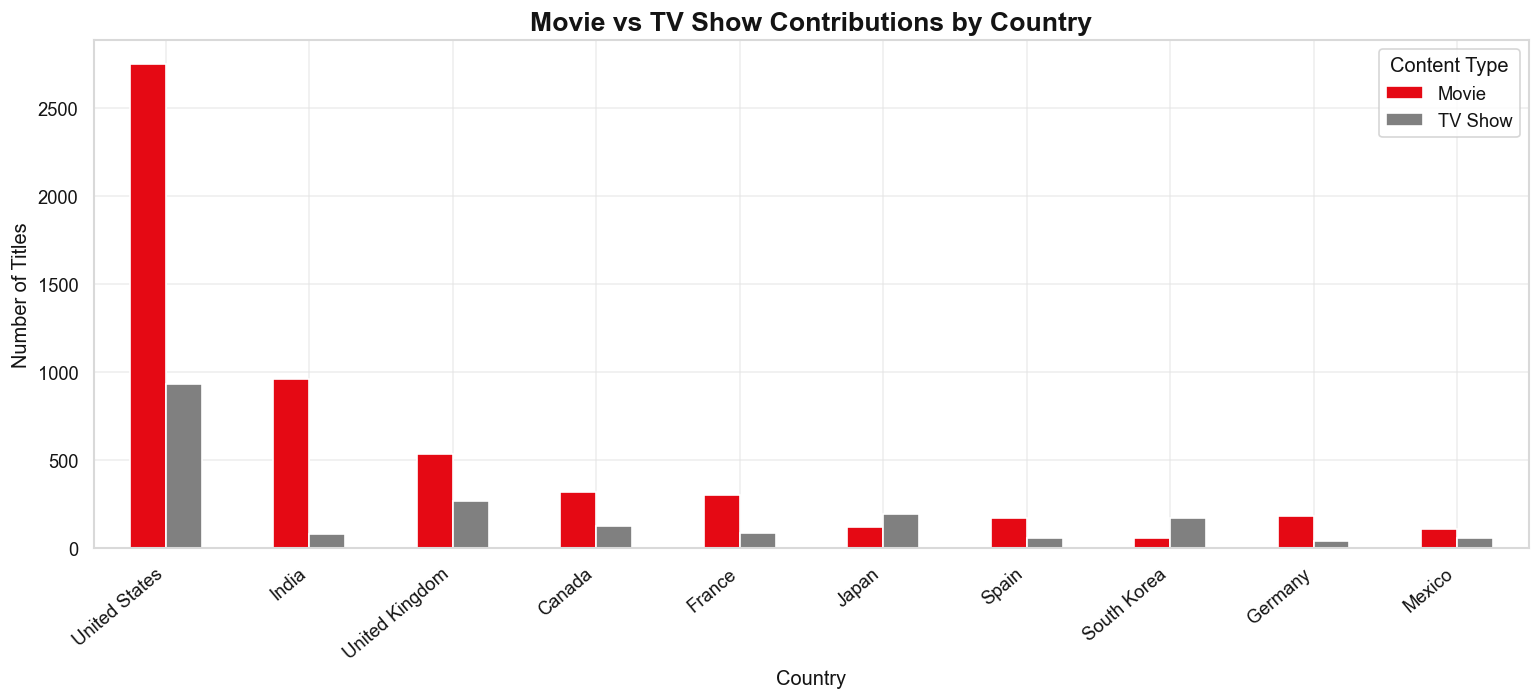

In [38]:
country_type = df[["show_id", "type", "country"]].copy()

country_type["country"] = country_type["country"].str.split(",")

country_type = country_type.explode("country")

country_type["country"] = country_type["country"].str.strip()

country_type = country_type[
    country_type["country"] != "Unknown Country"
]

top10 = country_counts.index

country_type_counts = (
    country_type[country_type["country"].isin(top10)]
    .groupby(["country", "type"])
    .size()
    .unstack(fill_value=0)
)

country_type_counts = country_type_counts.loc[top10]

country_type_counts.plot(
    kind="bar",
    figsize=(13, 6),
    color=[NETFLIX_RED, GREY]
)

plt.title("Movie vs TV Show Contributions by Country")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=40, ha="right")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

`Insight:`
- Different countries contribute differently to Netflix's movie and TV-show catalogue.
- Some markets may have a stronger movie presence, while others may contribute relatively more television content.
- This variation highlights the importance of understanding regional content production patterns.

`Business recommendation:` Develop region-specific acquisition strategies based on local content availability and audience engagement.

### Analysis 7: What genres are most frequently represented in Netflix's catalogue?

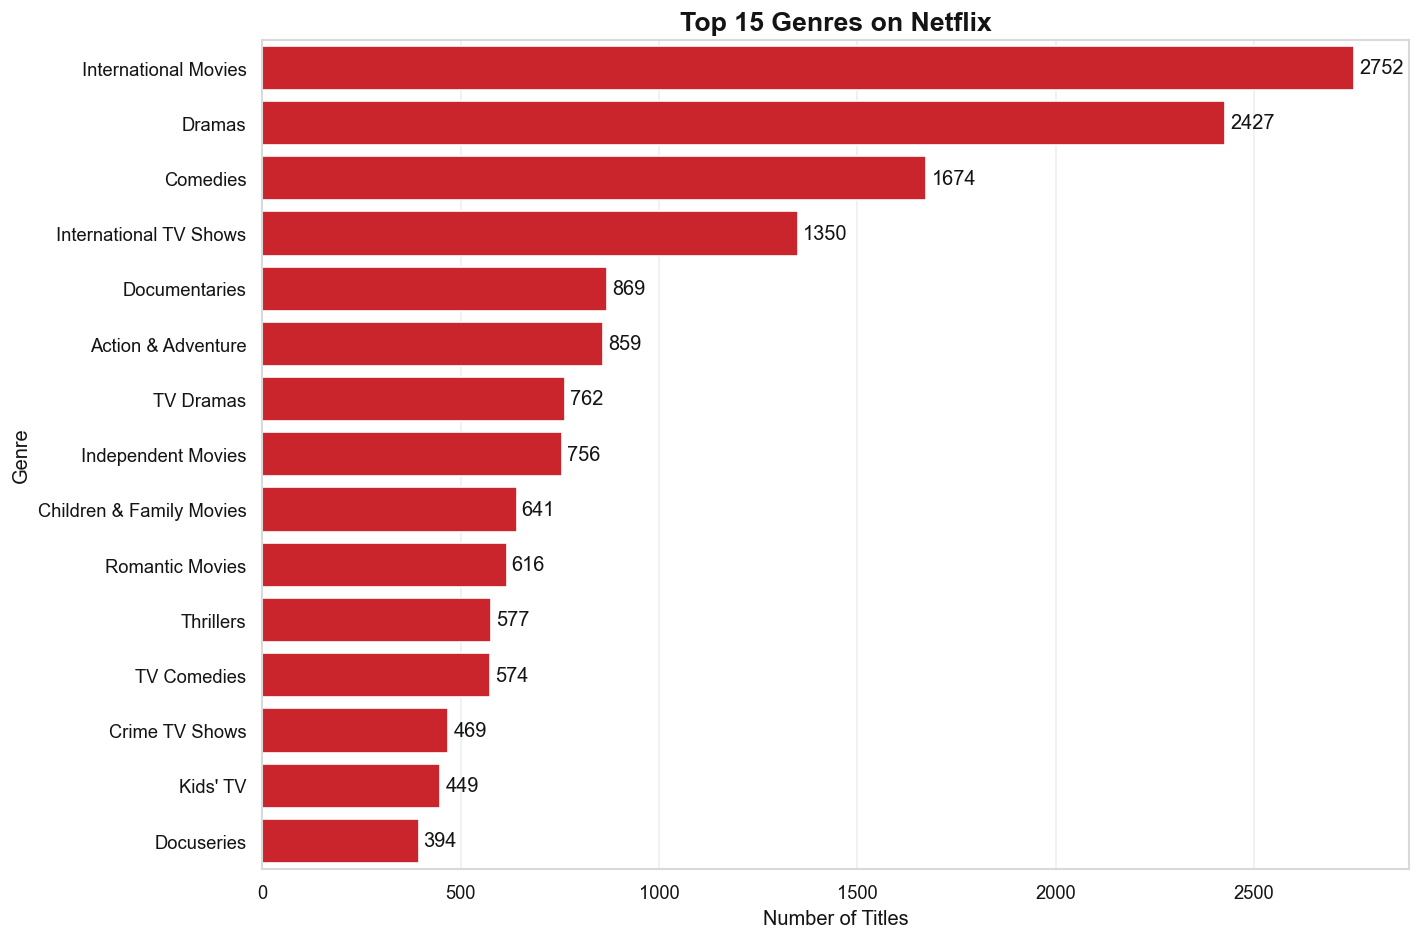

In [39]:
genre_data = df[["show_id", "listed_in"]].copy()

genre_data["listed_in"] = genre_data["listed_in"].str.split(",")

genre_data = genre_data.explode("listed_in")

genre_data["listed_in"] = genre_data["listed_in"].str.strip()

genre_counts = genre_data["listed_in"].value_counts().head(15)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 15 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

`Insight:`
- The genre analysis identifies the categories most frequently represented in Netflix's catalogue.
- Genres with high title counts have a stronger presence in the content library.
- Less represented genres may offer opportunities for catalogue diversification.

`Business recommendation:` Maintain popular genre categories while exploring underrepresented genres to broaden the content offering.

### Analysis 8: What content ratings are most common on Netflix?

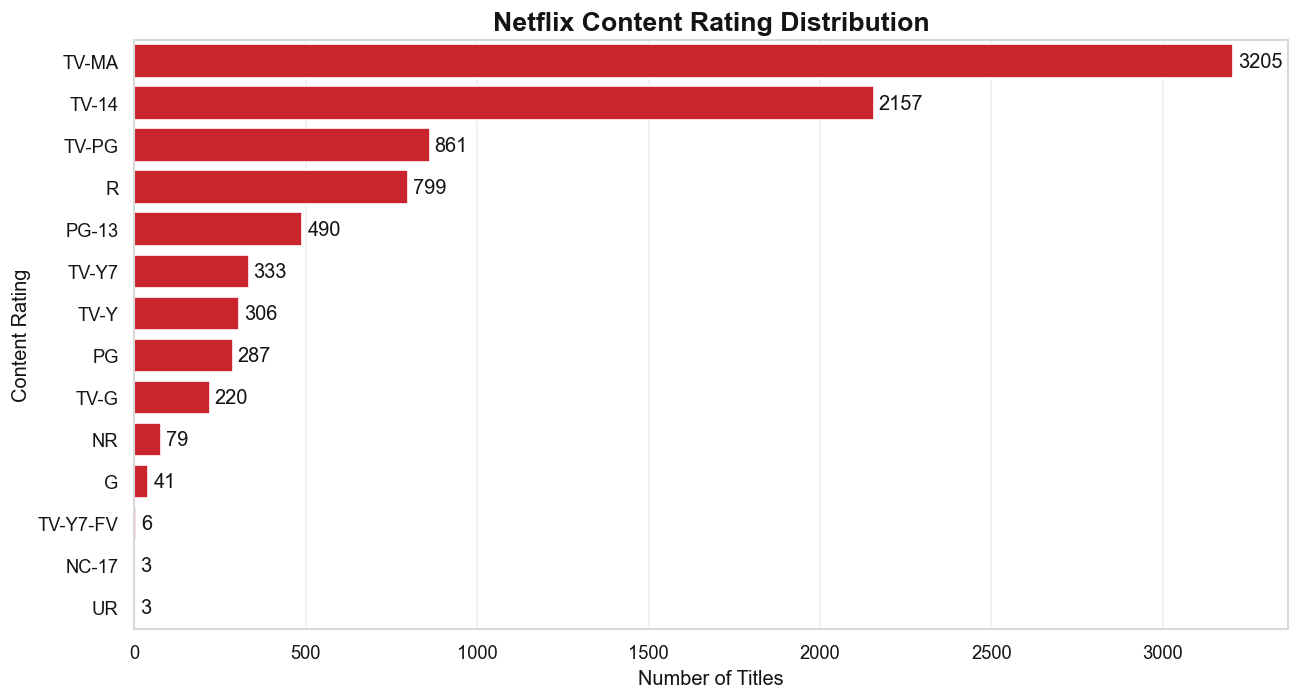

In [52]:
rating_counts = (
    df[df["rating"] != "Not Rated"]["rating"]
    .value_counts()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Netflix Content Rating Distribution")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()

`Insight:`
- The rating distribution helps identify the maturity levels most commonly represented in Netflix's catalogue.
- A high representation of mature-audience ratings indicates substantial catalogue coverage for adult audiences.
- Family-oriented ratings are also important for serving viewers looking for age-appropriate entertainment.

`Business recommendation:` Maintain a balanced content-rating portfolio to serve different audience segments, including families and mature viewers.

### Analysis 9: How many seasons do most Netflix TV shows have?

In [79]:
df["duration_value"] = (
    df["duration"]
    .str.extract(r"(\d+)")
    .astype(float))

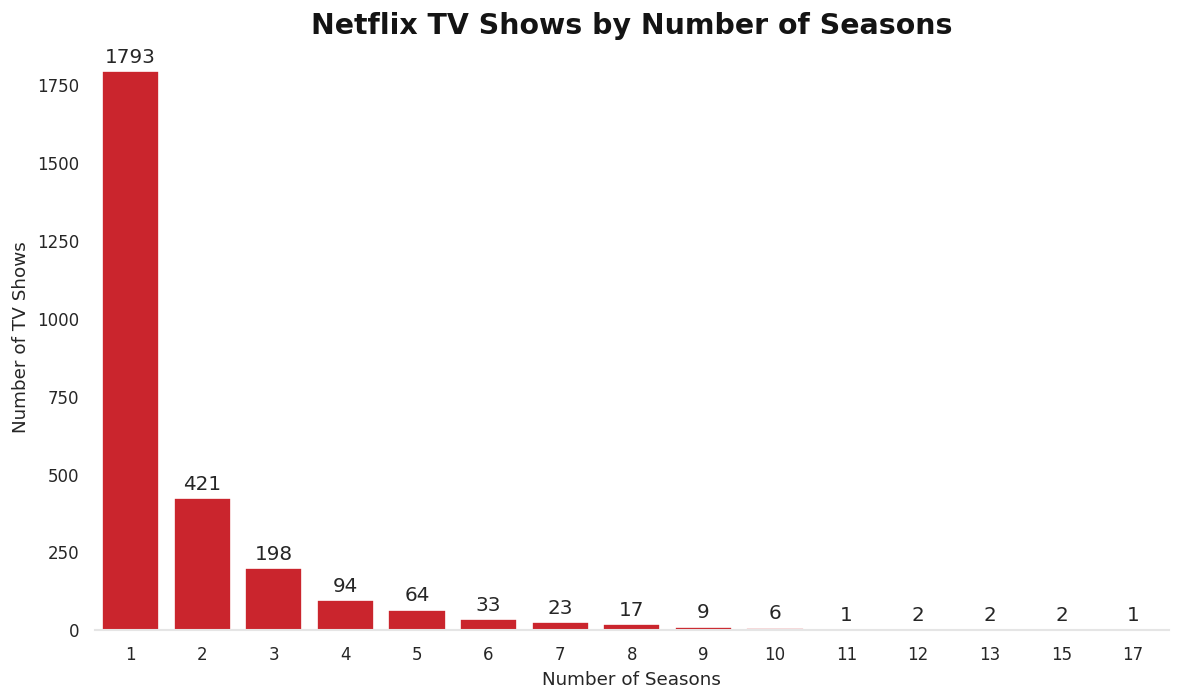

In [80]:
tv_seasons = df.loc[
    df["type"] == "TV Show", "duration_value"
].dropna()

season_counts = tv_seasons.value_counts().sort_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=season_counts.index.astype(int),
    y=season_counts.values,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Netflix TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()

`Insight:`
- The season distribution reveals whether Netflix's television catalogue is dominated by single-season or multi-season shows.
- A high concentration of one-season shows may indicate a catalogue with many shorter series.
- Multi-season shows provide opportunities for longer-running storytelling and audience retention.

`Business recommendation:` Evaluate the performance of multi-season content and identify opportunities to develop successful series into longer-running franchises.

### Analysis 10: How long after their original release were titles added to Netflix?

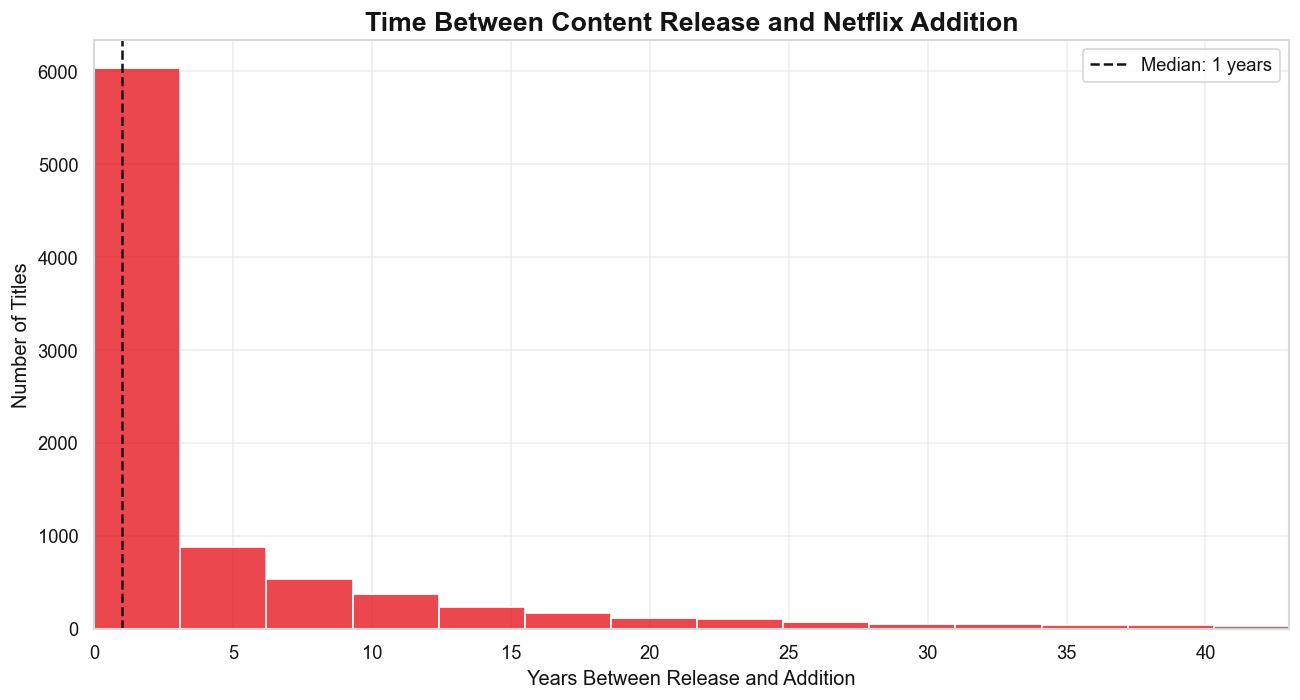

In [57]:
gap_data = df.copy()

gap_data["years_until_added"] = (
    gap_data["year_added"] - gap_data["release_year"]
)

gap_data = gap_data[
    gap_data["years_until_added"] >= 0
]

plt.figure(figsize=(11, 6))

sns.histplot(
    gap_data["years_until_added"],
    bins=30,
    color=NETFLIX_RED,
    edgecolor="white"
)

plt.axvline(
    gap_data["years_until_added"].median(),
    color=BLACK,
    linestyle="--",
    label=f"Median: {gap_data['years_until_added'].median():.0f} years"
)

plt.title("Time Between Content Release and Netflix Addition")
plt.xlabel("Years Between Release and Addition")
plt.ylabel("Number of Titles")
plt.xlim(0, gap_data["years_until_added"].quantile(0.99))
plt.legend()
plt.tight_layout()
plt.show()

`Insight:`
- The time difference between a title's original release and its addition to Netflix reveals the age of content at the time it entered the catalogue.
- A shorter acquisition gap indicates that titles were added relatively close to their original release.
- A longer gap demonstrates the presence of older catalogue content.

`Business recommendation:` Balance recently released titles with older content to maintain catalogue variety and potentially attract different audience segments.

### Analysis 11: Which decades contribute the most movies and TV shows to Netflix?

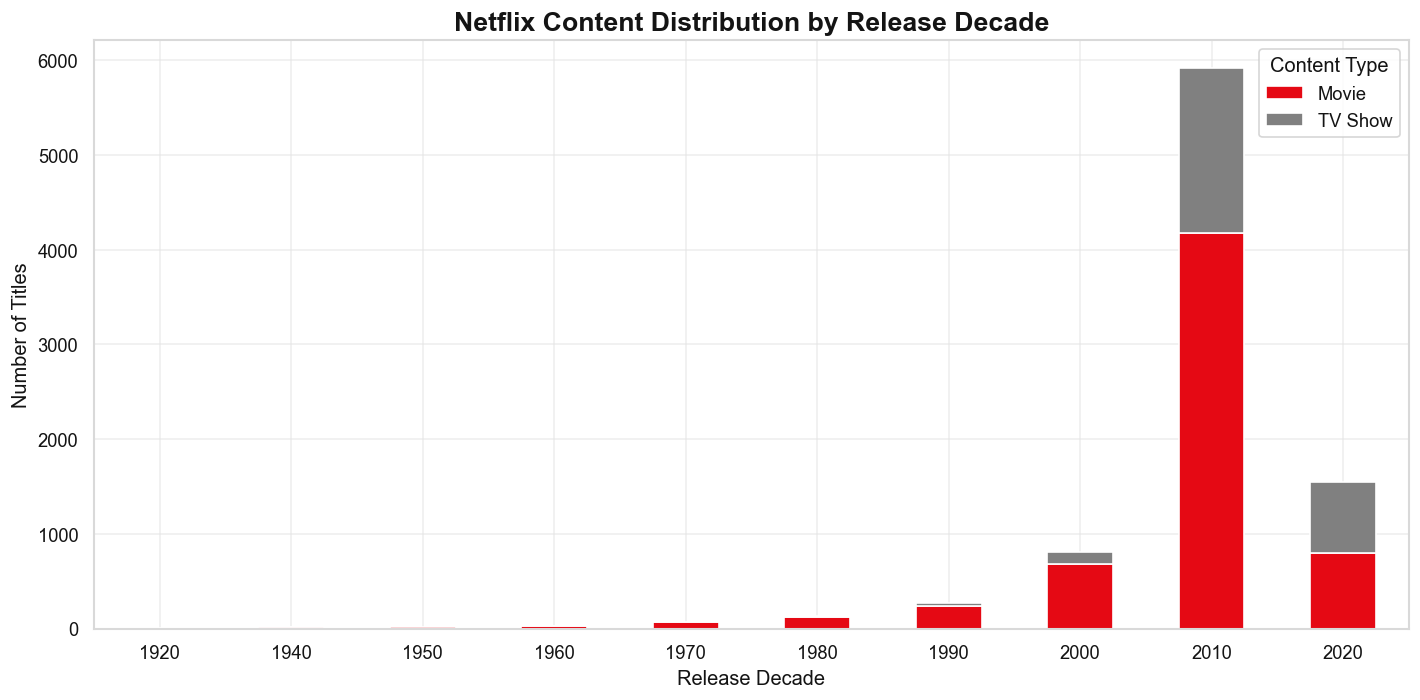

In [58]:
df["release_decade"] = (
    (df["release_year"] // 10) * 10
).astype(int)

decade_type = df.groupby(
    ["release_decade", "type"]
).size().unstack(fill_value=0)

decade_type.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=[NETFLIX_RED, GREY]
)

plt.title("Netflix Content Distribution by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

`Insight:`
- The decade-wise analysis reveals how much older and newer content is represented in Netflix's library.
- A higher concentration of recent decades indicates a strong presence of contemporary content.
- Older decades contribute historical variety and provide access to classic entertainment.

`Business recommendation:` Maintain a mix of contemporary and classic titles to serve viewers with different entertainment interests.

### Analysis 12: Which directors have the highest number of titles in the dataset?

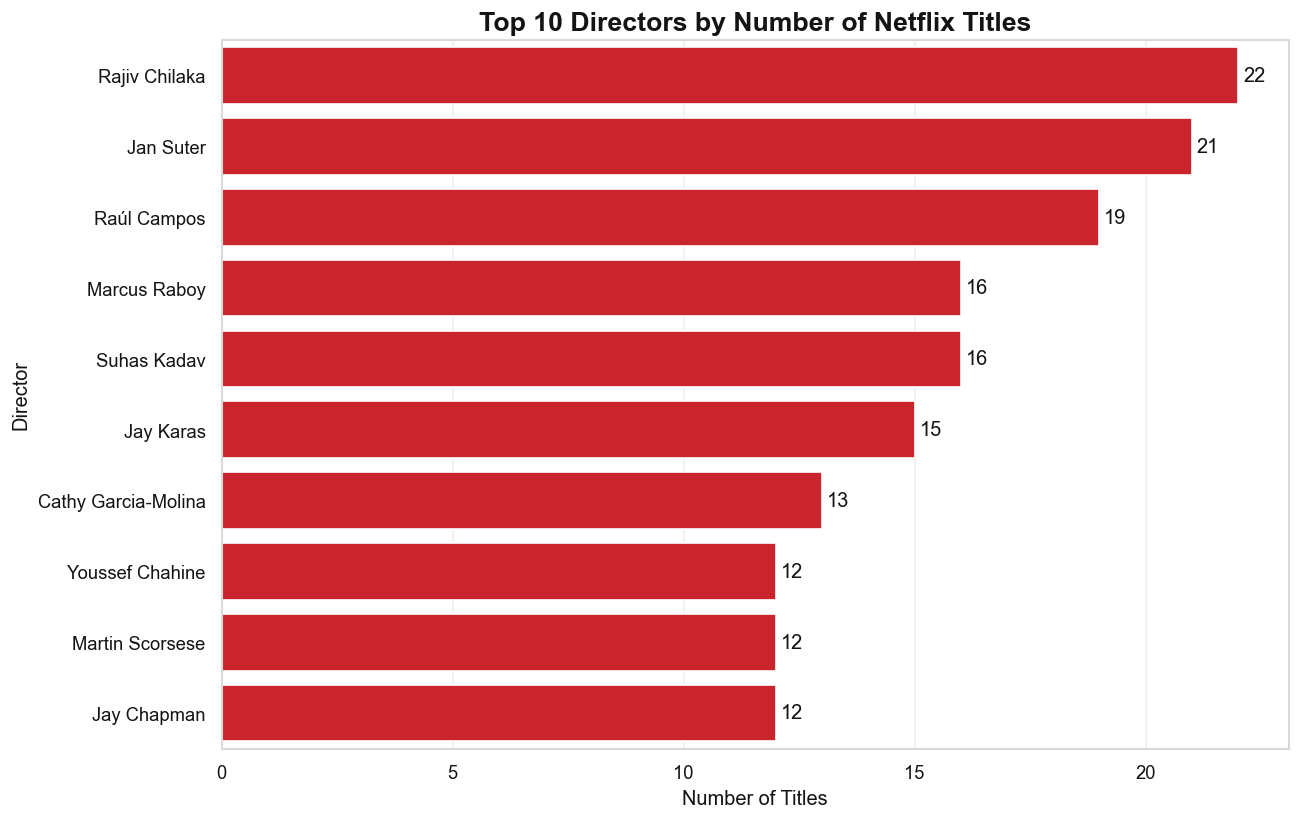

In [60]:
director_data = df[
    df["director"] != "Uncredited Director"
][["show_id", "director"]].copy()

director_data["director"] = director_data["director"].str.split(",")

director_data = director_data.explode("director")

director_data["director"] = director_data["director"].str.strip()

top_directors = director_data["director"].value_counts().head(10)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    x=top_directors.values,
    y=top_directors.index,
    color=NETFLIX_RED
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 Directors by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Director")
plt.tight_layout()
plt.show()

`Insight:`
- The director analysis identifies filmmakers with the highest number of titles in the dataset.
- Directors with multiple titles have a stronger representation in Netflix's catalogue.
- This analysis can help identify recurring creative contributors.

`Business recommendation:` Evaluate the contribution and performance of established filmmakers while continuing to discover emerging creative talent.

### Analysis 13: Movie vs TV Show genre comparison

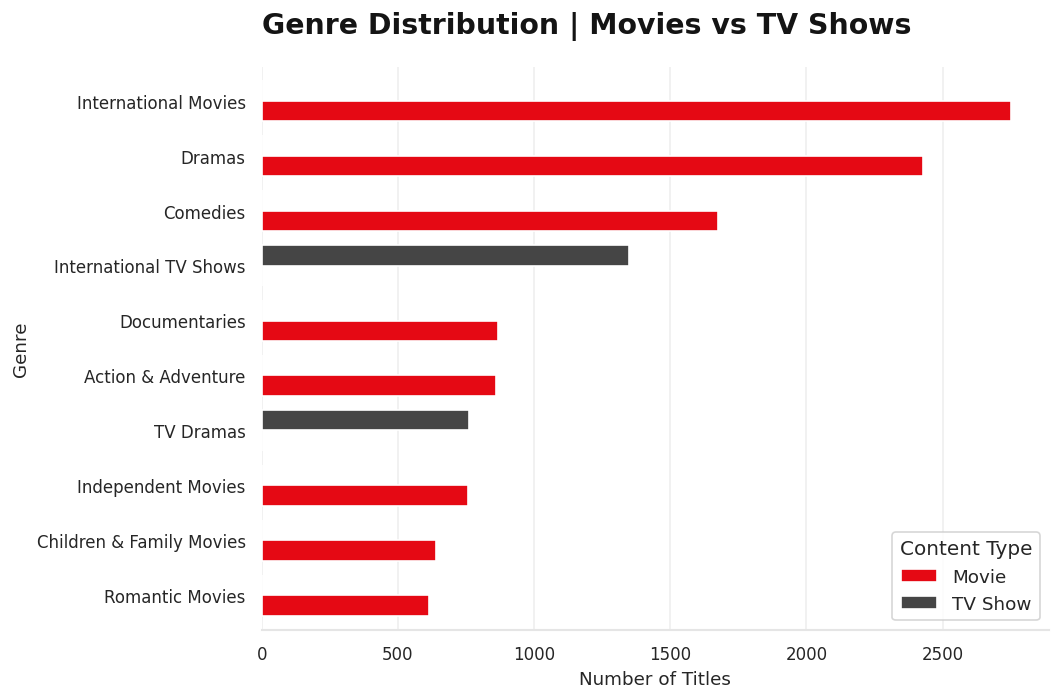

In [82]:
genre_type = df[["type", "listed_in"]].copy()

genre_type["listed_in"] = genre_type["listed_in"].str.split(",")

genre_type = genre_type.explode("listed_in")

genre_type["listed_in"] = genre_type["listed_in"].str.strip()

top_genres = (
    genre_type["listed_in"]
    .value_counts()
    .head(10)
    .index
)

genre_comparison = (
    genre_type[genre_type["listed_in"].isin(top_genres)]
    .groupby(["listed_in", "type"])
    .size()
    .unstack(fill_value=0)
)

genre_comparison = genre_comparison.loc[
    genre_comparison.sum(axis=1).sort_values().index
]

genre_comparison.plot(
    kind="barh",
    figsize=(9, 6),
    color=[NETFLIX_RED, DARK_GREY],
    width=0.75
)

plt.title(
    "Genre Distribution | Movies vs TV Shows",
    loc="left", pad=20
)

plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.legend(title="Content Type")
plt.grid(axis="x")

plt.tight_layout()
plt.show()

`Insight:`
- International Movies dominate the chart, followed by Dramas and Comedies.
- International TV Shows are the most represented TV category.
- Movies have a stronger presence than TV Shows across most displayed genres.
- Documentaries and Action & Adventure also contribute significantly to the movie catalogue.
- Netflix has an opportunity to further diversify its TV Show genres and international content

`Business Recommendation:`
- Invest in diverse international movies and TV Shows to strengthen global reach.
- Explore opportunities in less-represented genres to create a balanced content library.
- Increase investment in different TV Show genres to balance the movie-heavy catalogue.
- Develop content that reflects different cultures, languages and audiences.
- Balance dramas and comedies with documentaries, action and family-friendly content.

In [84]:
print("=" * 55)
print("       NETFLIX EDA | KEY BUSINESS INSIGHTS")
print("=" * 55)

# 1. Content distribution
content_share = df["type"].value_counts(normalize=True) * 100

print("\n1. CONTENT DISTRIBUTION")
print(content_share.round(2))

# 2. Peak addition year
yearly = df["year_added"].value_counts().sort_index()

print("\n2. PEAK CONTENT ADDITION YEAR")
print(yearly.idxmax(), "with", yearly.max(), "titles")

# 3. Most active month
monthly = df["month_name_added"].value_counts()

print("\n3. MOST ACTIVE MONTH")
print(monthly.idxmax(), "with", monthly.max(), "titles")

# 4. Top country
print("\n4. TOP CONTRIBUTING COUNTRY")

top_country = country_counts.index[0]
top_country_count = country_counts.iloc[0]

print(f"{top_country}: {top_country_count} titles")

# 5. Top genre
print("\n5. MOST REPRESENTED GENRE")
print(genre_counts.index[0], genre_counts.iloc[0], "assignments")

# 6. Acquisition gap
print("\n6. MEDIAN ACQUISITION GAP")
print(gap_data["years_until_added"].median(), "years")

# 7. TV seasons
print("\n7. MOST COMMON TV SHOW SEASON COUNT")
print(season_counts.idxmax(), "seasons")

       NETFLIX EDA | KEY BUSINESS INSIGHTS

1. CONTENT DISTRIBUTION
type
Movie      69.68
TV Show    30.32
Name: proportion, dtype: float64

2. PEAK CONTENT ADDITION YEAR
2019 with 2016 titles

3. MOST ACTIVE MONTH
July with 827 titles

4. TOP CONTRIBUTING COUNTRY
0: country    United States
count               3681
Name: 0, dtype: object titles

5. MOST REPRESENTED GENRE
International Movies 2752 assignments

6. MEDIAN ACQUISITION GAP
1.0 years

7. MOST COMMON TV SHOW SEASON COUNT
1.0 seasons


## 📊 Key Insights from Netflix Data Analysis

### 1. Content Distribution
- Movies account for approximately **69.6%** of the Netflix catalogue, while TV Shows represent **30.4%**.
- The catalogue has a stronger focus on movies than television series.
- Netflix could maintain this movie presence while exploring opportunities to expand its TV Show collection.

### 2. Content Release Trends
- The release-year analysis shows a strong concentration of titles from recent decades.
- More recent years contribute significantly to the available content.
- This indicates that the catalogue has a substantial focus on modern entertainment.

### 3. Netflix Content Additions Over Time
- Netflix's content additions vary across different years.
- The yearly trend helps identify periods of higher and lower catalogue expansion.
- These changes may reflect differences in content acquisition and catalogue expansion strategies.

### 4. Monthly Content Additions
- The monthly analysis reveals that Netflix does not add the same number of titles every month.
- Some months show higher content additions than others.
- This pattern can help identify periods when Netflix concentrated its catalogue updates.

### 5. Movies vs TV Shows Added
- Movies and TV Shows contribute differently to yearly content additions.
- Comparing both categories helps identify which format played a larger role in catalogue expansion during different years.
- Netflix can use this comparison when planning its future content mix.

### 6. Country-Wise Content Distribution
- The United States is the largest content contributor in the dataset.
- India and the United Kingdom are also important contributors.
- This highlights Netflix's international content presence and the importance of regional content markets.

### 7. Country-Wise Content Types
- The movie and TV Show comparison reveals differences in content formats across countries.
- Some countries contribute more movies, while others have a stronger representation of TV Shows.
- Netflix can use these patterns to understand the geographical composition of its catalogue.

### 8. Genre Analysis
- The genre analysis highlights the most frequently represented categories in the catalogue.
- Drama and international content categories have a notable presence.
- Genre distribution can help Netflix identify well-represented categories and areas worth exploring further.

### 9. Content Maturity Ratings
- TV-MA is the most common maturity rating in the dataset.
- This indicates a substantial representation of content intended for mature audiences.
- Netflix should continue maintaining a variety of maturity categories to serve different audience groups.

### 10. TV Show Season Distribution
- The season analysis helps understand how TV Shows are distributed by number of seasons.
- Shows with fewer seasons form an important part of the catalogue.
- This provides useful information about the structure of Netflix's available television content.

### 11. Content Acquisition Gap
- The acquisition-gap analysis compares a title's original release year with the year it was added to Netflix.
- It helps distinguish recently released titles from older content added to the platform later.
- Netflix can use this analysis to understand the balance between newer releases and catalogue additions.

### 12. Decade-Wise Content Distribution
- The decade analysis shows how the catalogue is distributed across different release periods.
- It helps identify Netflix's representation of both classic and modern content.
- Maintaining a mix of older and newer titles can support a diverse catalogue.

### 13. Director Analysis
- The director analysis identifies filmmakers with the highest number of titles in the catalogue.
- It highlights directors who have contributed multiple titles.
- This can help explore recurring creative contributors, although title count alone does not measure popularity or success.

---

## 💡 Overall Business Insights

1. **Content Portfolio:** Netflix has a movie-heavy catalogue, so maintaining a balanced mix of movies and TV Shows is worth considering.

2. **Global Expansion:** The strong representation of the United States, India and the United Kingdom highlights the importance of international content.

3. **Genre Opportunities:** Genre analysis can help identify heavily represented categories and potential opportunities to diversify the catalogue.

4. **Audience Segmentation:** The maturity-rating distribution can support content planning for different age groups.

5. **Content Acquisition:** Analysing the acquisition gap can help Netflix understand its balance between recently released and older titles.

6. **Catalogue Planning:** Yearly and monthly addition trends can support better planning of future catalogue expansion.

---

## 📝 Conclusion

This Exploratory Data Analysis of Netflix's catalogue provides insights into content distribution, release trends, country-wise contributions, genres, maturity ratings and content acquisition patterns.

The analysis highlights Netflix's movie-focused catalogue, its international content presence and the importance of maintaining a diverse content portfolio.

These findings can support better catalogue planning, content diversification and regional content strategies.

**Note:** This dataset contains catalogue metadata up to 2021. It does not include actual viewing hours, revenue, subscriber behaviour or audience preferences. Therefore, these findings describe catalogue patterns rather than content performance or popularity.
